In [ ]:
!pip install segmentation-models

I0000 00:00:1786659796.596382   13208 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
W0000 00:00:1786659908.994941   13208 gpu_bfc_allocator.cc:47] Overriding orig_value setting because the TF_FORCE_GPU_ALLOW_GROWTH environment variable is set. Original config value was false.
I0000 00:00:1786659908.995461   13208 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 5563 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 4060 Laptop GPU, pci bus id: 0000:01:00.0, compute capability: 8.9


Running U-Net Inference...


I0000 00:00:1786659912.024314   20088 service.cc:153] XLA service 0x7d101c0068c0 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1786659912.024365   20088 service.cc:161]   StreamExecutor [0]: NVIDIA GeForce RTX 4060 Laptop GPU, Compute Capability 8.9 (Driver: 12.7.0; Runtime: 12.9.0; Toolkit: 12.5.0; DNN: 9.21.1)
I0000 00:00:1786659912.138688   20088 dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1786659912.328411   20088 cuda_dnn.cc:461] Loaded cuDNN version 92101
W0000 00:00:1786659916.089768   20088 bfc_allocator.cc:383] Garbage collection: deallocate free memory regions (i.e., allocations) so that we can re-allocate a larger region to avoid OOM due to memory fragmentation. If you see this message frequently, you are running near the threshold of the available device memory and re-allocation may incur great performance overhead. You may try smaller batch

1/1 ━━━━━━━━━━━━━━━━━━━━ 11s 11s/step


I0000 00:00:1786659922.867953   20088 device_compiler.h:208] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


Result saved successfully as 'unet_comparison.png'!


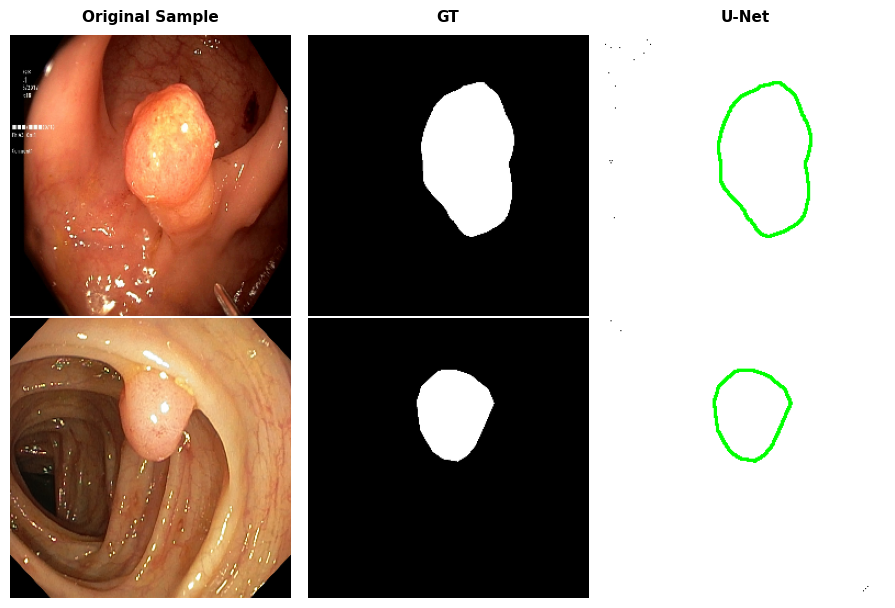

In [2]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, models

# ==========================================
# ১. Pure Keras-এ U-Net মডেল আর্কিটেকচার
# ==========================================
def build_unet(input_shape=(256, 256, 3)):
    inputs = layers.Input(input_shape)

    # Encoder (Contracting Path)
    c1 = layers.Conv2D(32, (3, 3), activation='relu', padding='same')(inputs)
    c1 = layers.Conv2D(32, (3, 3), activation='relu', padding='same')(c1)
    p1 = layers.MaxPooling2D((2, 2))(c1)

    c2 = layers.Conv2D(64, (3, 3), activation='relu', padding='same')(p1)
    c2 = layers.Conv2D(64, (3, 3), activation='relu', padding='same')(c2)
    p2 = layers.MaxPooling2D((2, 2))(c2)

    c3 = layers.Conv2D(128, (3, 3), activation='relu', padding='same')(p2)
    c3 = layers.Conv2D(128, (3, 3), activation='relu', padding='same')(c3)
    p3 = layers.MaxPooling2D((2, 2))(c3)

    # Bottleneck
    c4 = layers.Conv2D(256, (3, 3), activation='relu', padding='same')(p3)
    c4 = layers.Conv2D(256, (3, 3), activation='relu', padding='same')(c4)

    # Decoder (Expanding Path)
    u5 = layers.Conv2DTranspose(128, (2, 2), strides=(2, 2), padding='same')(c4)
    u5 = layers.concatenate([u5, c3])
    c5 = layers.Conv2D(128, (3, 3), activation='relu', padding='same')(u5)
    c5 = layers.Conv2D(128, (3, 3), activation='relu', padding='same')(c5)

    u6 = layers.Conv2DTranspose(64, (2, 2), strides=(2, 2), padding='same')(c5)
    u6 = layers.concatenate([u6, c2])
    c6 = layers.Conv2D(64, (3, 3), activation='relu', padding='same')(u6)
    c6 = layers.Conv2D(64, (3, 3), activation='relu', padding='same')(c6)

    u7 = layers.Conv2DTranspose(32, (2, 2), strides=(2, 2), padding='same')(c6)
    u7 = layers.concatenate([u7, c1])
    c7 = layers.Conv2D(32, (3, 3), activation='relu', padding='same')(u7)
    c7 = layers.Conv2D(32, (3, 3), activation='relu', padding='same')(c7)

    # Output Layer
    outputs = layers.Conv2D(1, (1, 1), activation='sigmoid')(c7)

    model = models.Model(inputs=[inputs], outputs=[outputs], name="U-Net")
    return model

# ==========================================
# ২. ইমেজ প্রসেসিং ও কনটুর ওভারলে ফাংশন
# ==========================================
def load_and_preprocess(img_path, gt_path, img_size=(256, 256)):
    """ইমেজ এবং জিটি মাস্ক লোড ও সাইজ ঠিক করার ফাংশন"""
    # Original Image Load
    img = cv2.imread(img_path)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    img_resized = cv2.resize(img, img_size)
    img_normalized = img_resized / 255.0  # Normalization

    # GT Mask Load
    gt = cv2.imread(gt_path, cv2.IMREAD_GRAYSCALE)
    gt_resized = cv2.resize(gt, img_size)

    return img_resized, img_normalized, gt_resized

def draw_gt_contour(pred_mask, gt_mask, contour_color=(0, 255, 0), thickness=2):
    """
    প্রেডিকশন মাস্কের ওপর Ground Truth এর সবুজ আউটলাইন ওভারলে করা।
    """
    pred_mask = np.squeeze(pred_mask)
    gt_mask = np.squeeze(gt_mask)

    # Thresholding
    pred_bin = (pred_mask > 0.5).astype(np.uint8) * 255
    gt_bin = (gt_mask > 127).astype(np.uint8) * 255

    # Black & White Prediction to RGB
    pred_rgb = cv2.cvtColor(pred_bin, cv2.COLOR_GRAY2RGB)

    # Find GT Contour
    contours, _ = cv2.findContours(gt_bin, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

    # Overlay Contour
    overlay_img = pred_rgb.copy()
    cv2.drawContours(overlay_img, contours, -1, contour_color, thickness)

    return overlay_img

# ==========================================
# ৩. মূল রান ও ভিজ্যুয়ালাইজেশন ফাংশন
# ==========================================
def run_unet_pipeline(image_paths, gt_paths, weights_path=None, img_size=(256, 256), save_output="unet_result.png"):
    num_samples = len(image_paths)
    
    # U-Net মডেল ইনিশিয়ালাইজেশন
    model = build_unet(input_shape=(img_size[0], img_size[1], 3))
    
    # ট্রেইন করা ওয়েট থাকলে লোড করা
    if weights_path and os.path.exists(weights_path):
        print(f"Loading weights from {weights_path}...")
        model.load_weights(weights_path)
    else:
        print("Warning: No weights path provided. Running model with random weights for structure testing!")

    # প্রেডিকশনের জন্য ডাটা রেডি করা
    orig_images = []
    norm_images = []
    gt_masks = []

    for img_p, gt_p in zip(image_paths, gt_paths):
        orig, norm, gt = load_and_preprocess(img_p, gt_p, img_size=img_size)
        orig_images.append(orig)
        norm_images.append(norm)
        gt_masks.append(gt)

    norm_images_array = np.array(norm_images)

    # Model Inference
    print("Running U-Net Inference...")
    predictions = model.predict(norm_images_array)

    # Plotting (3 Columns: Original, GT, U-Net)
    fig, axes = plt.subplots(num_samples, 3, figsize=(9, num_samples * 3))
    
    # যদি একটি মাত্র ইমেজ থাকে
    if num_samples == 1:
        axes = np.expand_dims(axes, axis=0)

    column_titles = ["Original Sample", "GT", "U-Net"]

    for i in range(num_samples):
        # Col 0: Original
        axes[i, 0].imshow(orig_images[i])
        
        # Col 1: GT Mask
        axes[i, 1].imshow(gt_masks[i], cmap='gray')
        
        # Col 2: U-Net Prediction with GT Contour
        overlaid = draw_gt_contour(predictions[i], gt_masks[i])
        axes[i, 2].imshow(overlaid)

    # Column Titles
    for j, title in enumerate(column_titles):
        axes[0, j].set_title(title, fontsize=11, fontweight='bold', pad=10)

    # Hide Axes
    for ax in axes.ravel():
        ax.axis('off')

    plt.tight_layout(pad=0.5)
    plt.savefig(save_output, dpi=300, bbox_inches='tight')
    print(f"Result saved successfully as '{save_output}'!")
    plt.show()

# ==========================================
# ৪. স্ক্রিপ্টটি যেভাবে ব্যবহার করবেন
# ==========================================
if __name__ == "__main__":
    
    # এখানে আপনার ইমেজের পাথগুলো দিন
    sample_images = [
        "/mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C2/images_C2/EndoCV2021_001304.jpg",
        "/mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C1/images_C1/459OLCV1_100H0006.jpg",
    ]

    # এখানে আপনার Ground Truth (GT) মাস্কের পাথগুলো দিন
    sample_gts = [
         "/mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C2/masks_C2/EndoCV2021_001304_mask.jpg",
        "/mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C1/masks_C1/459OLCV1_100H0006_mask.jpg",


    ]

    # আপনার U-Net এর Saved Weights ফাইল (.h5 / .keras) থাকলে তার পাথ দিন, না থাকলে None রাখুন
    WEIGHTS_PATH = "path/to/unet_weights.h5"  # or None

    # রান করুন
    run_unet_pipeline(
        image_paths=sample_images,
        gt_paths=sample_gts,
        weights_path=WEIGHTS_PATH,
        img_size=(256, 256),
        save_output="unet_comparison.png"
    )

In [4]:
@tf.keras.utils.register_keras_serializable()
class KerasPCCLayer(layers.Layer):
    """Natively computes spatial Pearson Correlation Coefficients within the network graph."""
    def __init__(self, **kwargs):
        super(KerasPCCLayer, self).__init__(**kwargs)

    def call(self, inputs):
        # We used epsilon sothat standard deviation value cannot be zero, otherwise code will crash
        epsilon = 1e-8
        # finds the average standard deviaiton
        mean = tf.reduce_mean(inputs, axis=-1, keepdims=True)
        std = tf.math.reduce_std(inputs, axis=-1, keepdims=True) + epsilon
        # data normalization or (Z-Score)
        norm_inputs = (inputs - mean) / std
        pcc_matrix = tf.matmul(tf.expand_dims(norm_inputs, -1), tf.expand_dims(norm_inputs, 1))
        return layers.Flatten()(pcc_matrix)

Loading models into memory...
[+] Loaded: U-Net
[+] Loaded: ResNet


E0000 00:00:1786674308.106845   20091 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1786674311.216754   20091 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.



Success! Comparison saved to 'multimodel_errormap.png'


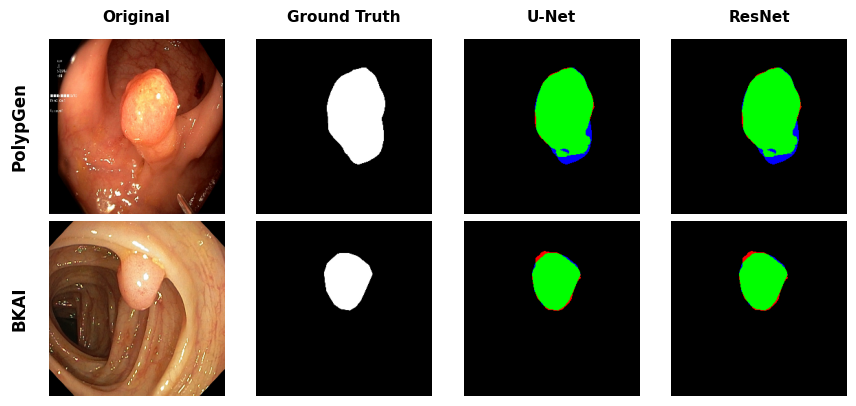

In [5]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

# ==========================================
# ১. Error Map জেনারেট করার ফাংশন
# ==========================================
def generate_error_map(pred_mask, gt_mask):
    """
    প্রেডিকশন এবং জিটি মাস্ক তুলনা করে কালার-কোডেড Error Map তৈরি করে।
    pred_mask এবং gt_mask 2D array (0 থেকে 1 স্কেলে) হতে হবে।
    """
    pred_mask = np.squeeze(pred_mask)
    gt_mask = np.squeeze(gt_mask)

    # Thresholding (0.5 এর ওপর হলে 1, নাহলে 0)
    pred_bin = (pred_mask > 0.5).astype(np.uint8)
    gt_bin = (gt_mask > 0.5).astype(np.uint8)

    # কালার ম্যাপ তৈরি করার জন্য ব্ল্যাঙ্ক RGB ক্যানভাস (Black background)
    error_map = np.zeros((pred_bin.shape[0], pred_bin.shape[1], 3), dtype=np.uint8)

    # True Positive (TP) -> Green (0, 255, 0)
    tp = (pred_bin == 1) & (gt_bin == 1)
    error_map[tp] = [0, 255, 0]

    # False Positive (FP) -> Red (255, 0, 0)
    fp = (pred_bin == 1) & (gt_bin == 0)
    error_map[fp] = [255, 0, 0]

    # False Negative (FN) -> Blue (0, 0, 255)
    fn = (pred_bin == 0) & (gt_bin == 1)
    error_map[fn] = [0, 0, 255]

    return error_map

# ==========================================
# ২. ইমেজ এবং মাস্ক লোডিং ফাংশন
# ==========================================
def load_image_and_mask(img_path, mask_path, target_size=(256, 256)):
    # Original Image
    img = cv2.imread(img_path)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    img_resized = cv2.resize(img, target_size)
    img_normalized = img_resized / 255.0  # Normalization [0, 1] for TF models

    # GT Mask
    mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)
    mask_resized = cv2.resize(mask, target_size)
    mask_normalized = mask_resized / 255.0  # Normalization [0, 1]

    return img_resized, img_normalized, mask_resized, mask_normalized

# ==========================================
# ৩. মূল ভিজ্যুয়ালাইজেশন পাইপলাইন
# ==========================================
def plot_multi_model_error_maps(image_paths, mask_paths, dataset_names, model_dict, target_size=(256, 256), save_name="error_map_comparison.png"):
    num_samples = len(image_paths)
    model_names = list(model_dict.keys())
    loaded_models = {}

    print("Loading models into memory...")
    for name, path in model_dict.items():
        if os.path.exists(path):
            # compile=False দিলে লোডিং ফাস্ট হয় এবং কাস্টম লসের এরর এড়ানো যায়
            loaded_models[name] = tf.keras.models.load_model(path, compile=False)
            print(f"[+] Loaded: {name}")
        else:
            print(f"[-] Model path not found for {name}: {path}")

    valid_model_names = list(loaded_models.keys())
    num_cols = 2 + len(valid_model_names) # Original + GT + Valid Models

    fig, axes = plt.subplots(num_samples, num_cols, figsize=(num_cols * 2.2, num_samples * 2))
    
    # 1D array হ্যান্ডেল করার জন্য যদি মাত্র ১টি ইমেজ থাকে
    if num_samples == 1:
        axes = np.expand_dims(axes, axis=0)

    column_titles = ["Original", "Ground Truth"] + valid_model_names

    for i in range(num_samples):
        # ডাটা লোড
        orig_img, norm_img, gt_mask, norm_gt = load_image_and_mask(image_paths[i], mask_paths[i], target_size)
        
        # Batch ডাইমেনশন অ্যাড করা (1, H, W, C)
        input_tensor = np.expand_dims(norm_img, axis=0)

        # Col 0: Original Image
        axes[i, 0].imshow(orig_img)
        # একদম বামের কলামে ডেটাসেটের নাম সেট করা (Y-Axis Label হিসেবে)
        axes[i, 0].set_ylabel(dataset_names[i], fontsize=12, fontweight='bold', rotation=90, labelpad=15)
        
        # Col 1: Ground Truth (Grayscale)
        axes[i, 1].imshow(gt_mask, cmap='gray')

        # Col 2 to N: Models Inference & Error Maps
        for j, m_name in enumerate(valid_model_names):
            model = loaded_models[m_name]
            
            # Prediction
            pred = model.predict(input_tensor, verbose=0)
            
            # Error Map জেনারেট
            error_map_img = generate_error_map(pred_mask=pred[0], gt_mask=norm_gt)
            
            axes[i, j + 2].imshow(error_map_img)

    # কলামের টাইটেল সেট করা (শুধুমাত্র উপরের সারিতে)
    for j, title in enumerate(column_titles):
        axes[0, j].set_title(title, fontsize=11, fontweight='bold', pad=12)

    # X এবং Y Axis এর দাগ মুছে দেওয়া, কিন্তু ডেটাসেট লেবেল যেন মুছে না যায়
    for i in range(num_samples):
        for j in range(num_cols):
            axes[i, j].set_xticks([])
            axes[i, j].set_yticks([])
            # Spines (বর্ডার) হাইড করা
            for spine in axes[i, j].spines.values():
                spine.set_visible(False)

    plt.tight_layout(pad=0.5)
    plt.savefig(save_name, dpi=300, bbox_inches='tight', facecolor='white')
    print(f"\nSuccess! Comparison saved to '{save_name}'")
    plt.show()

# ==========================================
# ৪. আপনার ভ্যারিয়েবল এবং এক্সিকিউশন
# ==========================================
if __name__ == "__main__":
    
    # আপনার ইমেজ এবং মাস্ক পাথগুলো এখানে দিন
    image_path_array = [
 "/mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C2/images_C2/EndoCV2021_001304.jpg",
        "/mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C1/images_C1/459OLCV1_100H0006.jpg"
    ]
    
    mask_path_array = [
         "/mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C2/masks_C2/EndoCV2021_001304_mask.jpg",
        "/mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C1/masks_C1/459OLCV1_100H0006_mask.jpg"
    ]
    
    # ডেটাসেটের নামগুলো
    datasetName = ["PolypGen", "BKAI"]

    # মডেলের নাম এবং তাদের সেভড ফাইলের (.h5) পাথ
    models_dict = {
        "U-Net": "/mnt/c/development/Thesis/PolypSegmentationBasedClassification/models/SC/tr-elm/thesis_v3_sequential_v_eval_data_driven_v2.keras",
        "ResNet": "/mnt/c/development/Thesis/PolypSegmentationBasedClassification/models/SC/tr-elm/thesis_v3_sequential_v_eval_data_driven_v2.keras"
    }

    # ফাংশন কল
    plot_multi_model_error_maps(
        image_paths=image_path_array,
        mask_paths=mask_path_array,
        dataset_names=datasetName,
        model_dict=models_dict,
        target_size=(256, 256),     # আপনার মডেল ইনপুট অনুযায়ী চেঞ্জ করে নিবেন
        save_name="multimodel_errormap.png"
    )

Loading models into memory...
[+] Loaded: U-Net
[+] Loaded: ResNet

Success! Comparison saved to 'multimodel_errormap.png'


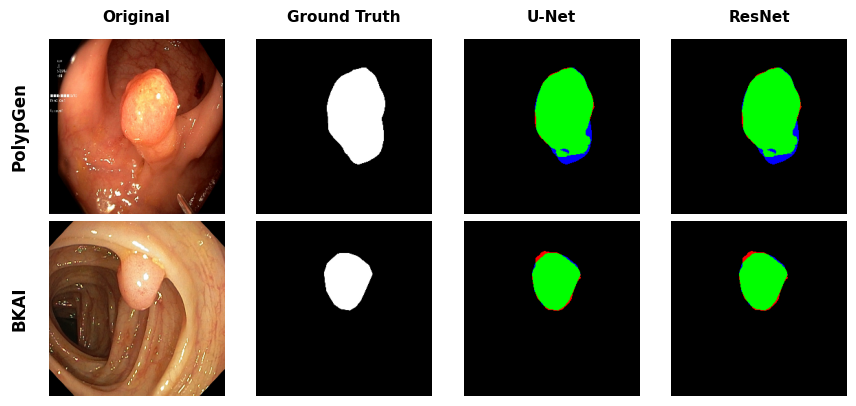

In [7]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

# ==========================================
# ১. Error Map জেনারেট করার ফাংশন (Clean & Accurate)
# ==========================================
def generate_error_map(pred_mask, gt_mask):
    """
    True Positive (Green), False Positive (Red), False Negative (Blue) দিয়ে Error Map তৈরি করে।
    """
    pred_mask = np.squeeze(pred_mask)
    gt_mask = np.squeeze(gt_mask)

    # Thresholding (0.5 এর বেশি হলে 1, অন্যথায় 0)
    pred_bin = (pred_mask > 0.5).astype(np.uint8)
    
    if gt_mask.max() > 1.0:
        gt_bin = (gt_mask > 127).astype(np.uint8)
    else:
        gt_bin = (gt_mask > 0.5).astype(np.uint8)

    # Black Background RGB Canvas
    error_map = np.zeros((pred_bin.shape[0], pred_bin.shape[1], 3), dtype=np.uint8)

    # 1. True Positive (TP) -> Green (0, 255, 0)
    tp = (pred_bin == 1) & (gt_bin == 1)
    error_map[tp] = [0, 255, 0]

    # 2. False Positive (FP) -> Red (255, 0, 0)
    fp = (pred_bin == 1) & (gt_bin == 0)
    error_map[fp] = [255, 0, 0]

    # 3. False Negative (FN) -> Blue (0, 0, 255)
    fn = (pred_bin == 0) & (gt_bin == 1)
    error_map[fn] = [0, 0, 255]

    return error_map

# ==========================================
# ২. ডেটা লোডিং ও প্রসেসিং ফাংশন
# ==========================================
# ==========================================
# ডেটা লোডিং ও প্রসেসিং ফাংশন (আপডেটেড)
# ==========================================
def load_image_and_mask(img_path, mask_path, target_size=(256, 256)):
    # Original Image
    img = cv2.imread(img_path)
    if img is None:
        raise FileNotFoundError(f"Image not found: {img_path}")
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    img_resized = cv2.resize(img, target_size)
    img_normalized = img_resized / 255.0  # [0, 1] for TF Model

    # GT Mask
    mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)
    if mask is None:
        raise FileNotFoundError(f"Mask not found: {mask_path}")
    mask_resized = cv2.resize(mask, target_size)
    mask_normalized = mask_resized / 255.0  # Normalized GT

    # এখন ৪টি ভ্যালু রিটার্ন করবে
    return img_resized, img_normalized, mask_resized, mask_normalized

# ==========================================
# ৩. প্রফেশনাল গ্রিড প্লটিং ও ভিজ্যুয়ালাইজেশন পাইপলাইন
# ==========================================
def plot_professional_comparison(image_paths, mask_paths, dataset_names, model_dict, target_size=(256, 256), save_name="professional_comparison.png"):
    num_samples = len(image_paths)
    model_names = list(model_dict.keys())
    loaded_models = {}

    print("Loading models into memory...")
    for name, path in model_dict.items():
        if os.path.exists(path):
            loaded_models[name] = tf.keras.models.load_model(path, compile=False)
            print(f"[+] Successfully Loaded Model: {name}")
        else:
            print(f"[-] Warning: Model path not found for '{name}' at '{path}'. Skipping this model.")

    valid_model_names = list(loaded_models.keys())
    if not valid_model_names:
        print("Error: No valid models loaded! Please check your model paths.")
        return

    num_cols = 2 + len(valid_model_names) # Original + Ground Truth + Models

    # পেপার-স্ট্যান্ডার্ড ফিগার সাইজ সেটআপ
    fig, axes = plt.subplots(num_samples, num_cols, figsize=(num_cols * 2.5, num_samples * 2.5))
    
    if num_samples == 1:
        axes = np.expand_dims(axes, axis=0)

    column_titles = ["Original", "Ground Truth"] + valid_model_names

    for i in range(num_samples):
        # ইমেজ এবং মাস্ক লোড করা
        orig_img, norm_img, gt_mask = load_image_and_mask(image_paths[i], mask_paths[i], target_size)
        input_tensor = np.expand_dims(norm_img, axis=0)

        # -------------------------------------------------------------
        # কলাম ১: Original Image (বামের সারিতে ডেটাসেটের নাম লেবেলিং সহ)
        # -------------------------------------------------------------
        axes[i, 0].imshow(orig_img)
        # সারির ঠিক বামপাশে ডেটাসেটের নাম খাড়াভাবে (Vertical) শো করার জন্য
        axes[i, 0].set_ylabel(dataset_names[i], fontsize=13, fontweight='bold', rotation=90, labelpad=15)
        
        # -------------------------------------------------------------
        # কলাম ২: Ground Truth Mask
        # -------------------------------------------------------------
        axes[i, 1].imshow(gt_mask, cmap='gray')

        # -------------------------------------------------------------
        # কলাম ৩ থেকে শেষ পর্যন্ত: বিভিন্ন মডেলের Error Map
        # -------------------------------------------------------------
        for j, m_name in enumerate(valid_model_names):
            model = loaded_models[m_name]
            
            # মডেল প্রেডিকশন
            pred = model.predict(input_tensor, verbose=0)
            
            # Error Map জেনरेट করা
            err_map = generate_error_map(pred_mask=pred[0], gt_mask=gt_mask)
            
            axes[i, j + 2].imshow(err_map)

    # -------------------------------------------------------------
    # টপ হেডার (কলামগুলোর নাম একদম ওপরের সারিতে সুন্দরভাবে সেট করা)
    # -------------------------------------------------------------
    for j, title in enumerate(column_titles):
        axes[0, j].set_title(title, fontsize=13, fontweight='bold', pad=15)

    # -------------------------------------------------------------
    # গ্রিড ক্লিনিং (অপ্রয়োজনীয় টিক ও বর্ডার রিমুভ করা)
    # -------------------------------------------------------------
    for i in range(num_samples):
        for j in range(num_cols):
            axes[i, j].set_xticks([])
            axes[i, j].set_yticks([])
            # শুধু প্রথম কলামের Y-axis লেবেলটি দৃশ্যমান রাখতে হবে, বাকি সব ফ্রেমিং ক্লিন করা
            if j > 0:
                axes[i, j].set_ylabel("")

    plt.tight_layout(pad=1.0)
    plt.savefig(save_name, dpi=300, bbox_inches='tight', facecolor='white')
    print(f"\n[✔] Professional Comparison Grid successfully saved as '{save_name}'!")
    plt.show()

# ==========================================
# ৪. আপনার ভ্যারিয়েবল এবং এক্সিকিউশন
# ==========================================
if __name__ == "__main__":
    
    # আপনার ইমেজ এবং মাস্ক পাথগুলো এখানে দিন
    image_path_array = [
 "/mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C2/images_C2/EndoCV2021_001304.jpg",
        "/mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C1/images_C1/459OLCV1_100H0006.jpg"
    ]
    
    mask_path_array = [
         "/mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C2/masks_C2/EndoCV2021_001304_mask.jpg",
        "/mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C1/masks_C1/459OLCV1_100H0006_mask.jpg"
    ]
    
    # ডেটাসেটের নামগুলো
    datasetName = ["PolypGen", "BKAI"]

    # মডেলের নাম এবং তাদের সেভড ফাইলের (.h5) পাথ
    models_dict = {
        "U-Net": "/mnt/c/development/Thesis/PolypSegmentationBasedClassification/models/SC/tr-elm/thesis_v3_sequential_v_eval_data_driven_v2.keras",
        "ResNet": "/mnt/c/development/Thesis/PolypSegmentationBasedClassification/models/SC/tr-elm/thesis_v3_sequential_v_eval_data_driven_v2.keras"
    }

    # ফাংশন কল
    plot_multi_model_error_maps(
        image_paths=image_path_array,
        mask_paths=mask_path_array,
        dataset_names=datasetName,
        model_dict=models_dict,
        target_size=(256, 256),     # আপনার মডেল ইনপুট অনুযায়ী চেঞ্জ করে নিবেন
        save_name="multimodel_errormap.png"
    )

In [ ]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

# ==========================================
# ১. Error Map জেনারেট করার ফাংশন (Healthy = Black)
# ==========================================
def generate_error_map(pred_mask, gt_mask):
    """
    - Healthy Tissue (True Negative) -> Black (0, 0, 0)
    - True Positive (TP) -> Green (0, 255, 0)
    - False Positive (FP) -> Red (255, 0, 0)
    - False Negative (FN) -> Blue (0, 0, 255)
    """
    pred_mask = np.squeeze(pred_mask)
    gt_mask = np.squeeze(gt_mask)

    # Thresholding (0.5 এর বেশি হলে 1, অন্যথায় 0)
    pred_bin = (pred_mask > 0.5).astype(np.uint8)
    
    if gt_mask.max() > 1.0:
        gt_bin = (gt_mask > 127).astype(np.uint8)
    else:
        gt_bin = (gt_mask > 0.5).astype(np.uint8)

    # ব্যাকগ্রাউন্ড তথা হেলদি টিস্যু ব্ল্যাক (0, 0, 0) দিয়ে শুরু হবে
    error_map = np.zeros((pred_bin.shape[0], pred_bin.shape[1], 3), dtype=np.uint8)

    # 1. True Positive (TP) -> Green (সঠিক পলিপ অংশ)
    tp = (pred_bin == 1) & (gt_bin == 1)
    error_map[tp] = [0, 255, 0]

    # 2. False Positive (FP) -> Red (অতিরিক্ত বা ভুল প্রেডিকশন)
    fp = (pred_bin == 1) & (gt_bin == 0)
    error_map[fp] = [255, 0, 0]

    # 3. False Negative (FN) -> Blue (মডেল মিস করেছে এমন অংশ)
    fn = (pred_bin == 0) & (gt_bin == 1)
    error_map[fn] = [0, 0, 255]

    return error_map

# ==========================================
# ২. ডেটা লোডিং ও প্রসেসিং ফাংশন
# ==========================================
def load_image_and_mask(img_path, mask_path, target_size=(256, 256)):
    # Original Image
    img = cv2.imread(img_path)
    if img is None:
        raise FileNotFoundError(f"Image not found: {img_path}")
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    img_resized = cv2.resize(img, target_size)
    img_normalized = img_resized / 255.0  # [0, 1] for TF Model

    # GT Mask
    mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)
    if mask is None:
        raise FileNotFoundError(f"Mask not found: {mask_path}")
    mask_resized = cv2.resize(mask, target_size)
    mask_normalized = mask_resized / 255.0  # Normalized GT

    return img_resized, img_normalized, mask_resized, mask_normalized

# ==========================================
# ৩. প্রফেশনাল কমপ্যাক্ট গ্রিড প্লটিং পাইপলাইন
# ==========================================
def plot_professional_comparison(image_paths, mask_paths, dataset_names, model_dict, target_size=(128, 256), save_name="final_thesis_comparison_grid.png"):
    num_samples = len(image_paths)
    loaded_models = {}

    print("Loading models into memory...")
    for name, path in model_dict.items():
        if os.path.exists(path):
            loaded_models[name] = tf.keras.models.load_model(path, compile=False)
            print(f"[+] Successfully Loaded Model: {name}")
        else:
            print(f"[-] Warning: Model path not found for '{name}' at '{path}'. Skipping this model.")

    valid_model_names = list(loaded_models.keys())
    if not valid_model_names:
        print("Error: No valid models loaded! Please check your model paths.")
        return

    num_cols = 2 + len(valid_model_names) # Original + Ground Truth + Models

    # বক্সের সাইজ ছোট করার জন্য মাল্টিপ্লায়ার কমিয়ে (1.6) করা হয়েছে
    fig, axes = plt.subplots(num_samples, num_cols, figsize=(num_cols * 1.1, num_samples * 1.0))
    
    if num_samples == 1:
        axes = np.expand_dims(axes, axis=0)

    # ইমেজগুলোর মাঝখানের স্পেস (Gap) কমানোর জন্য wspace এবং hspace কমানো হলো
    plt.subplots_adjust(wspace=0.09, hspace=0.009)

    column_titles = ["Original", "Ground Truth"] + valid_model_names

    for i in range(num_samples):
        orig_img, norm_img, gt_mask, norm_gt = load_image_and_mask(image_paths[i], mask_paths[i], target_size)
        input_tensor = np.expand_dims(norm_img, axis=0)

        # কলাম ১: Original Image (বামের সারিতে ডেটাসেটের নাম লেবেলিং)
        axes[i, 0].imshow(orig_img)
        axes[i, 0].set_ylabel(dataset_names[i], fontsize=11, fontweight='bold', rotation=90, labelpad=12)
        
        # কলাম ২: Ground Truth Mask
        axes[i, 1].imshow(gt_mask, cmap='gray')

        # কলাম ৩ থেকে শেষ পর্যন্ত: বিভিন্ন মডেলের Error Map
        for j, m_name in enumerate(valid_model_names):
            model = loaded_models[m_name]
            pred = model.predict(input_tensor, verbose=0)
            err_map = generate_error_map(pred_mask=pred[0], gt_mask=norm_gt)
            
            axes[i, j + 2].imshow(err_map)

    # টপ হেডার (কলামগুলোর নাম একদম ওপরের সারিতে)
    for j, title in enumerate(column_titles):
        axes[0, j].set_title(title, fontsize=11, fontweight='bold', pad=15)

    # গ্রিড ক্লিনিং
    for i in range(num_samples):
        for j in range(num_cols):
            axes[i, j].set_xticks([])
            axes[i, j].set_yticks([])
            if j > 0:
                axes[i, j].set_ylabel("")

    plt.savefig(save_name, dpi=300, bbox_inches='tight', facecolor='white')
    print(f"\n[✔] Compact & Professional Comparison Grid successfully saved as '{save_name}'!")
    plt.show()
# ==========================================
# ৪. আপনার ভ্যারিয়েবল এবং এক্সিকিউশন
# ==========================================
if __name__ == "__main__":
    
    # আপনার ইমেজ এবং মাস্ক পাথগুলো এখানে দিন
    image_path_array = [
 "/mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C2/images_C2/EndoCV2021_001304.jpg",
        "/mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C1/images_C1/459OLCV1_100H0006.jpg"
    ]
    
    mask_path_array = [
         "/mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C2/masks_C2/EndoCV2021_001304_mask.jpg",
        "/mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C1/masks_C1/459OLCV1_100H0006_mask.jpg"
    ]
    
    # ডেটাসেটের নামগুলো
    datasetName = ["PolypGen", "BKAI"]

    # মডেলের নাম এবং তাদের সেভড ফাইলের (.h5) পাথ
    models_dict = {
        "U-Net": "/mnt/c/development/Thesis/PolypSegmentationBasedClassification/models/SC/tr-elm/thesis_v3_sequential_v_eval_data_driven_v2.keras",
        "ResNet": "/mnt/c/development/Thesis/PolypSegmentationBasedClassification/models/SC/tr-elm/thesis_v3_sequential_v_eval_data_driven_v2.keras",
         "RAesNet": "/mnt/c/development/Thesis/PolypSegmentationBasedClassification/models/SC/tr-elm/thesis_v3_sequential_v_eval_data_driven_v2.keras",
         "RBesNet": "/mnt/c/development/Thesis/PolypSegmentationBasedClassification/models/SC/tr-elm/thesis_v3_sequential_v_eval_data_driven_v2.keras",
         "RCesNet": "/mnt/c/development/Thesis/PolypSegmentationBasedClassification/models/SC/tr-elm/thesis_v3_sequential_v_eval_data_driven_v2.keras",
         "RDesNet": "/mnt/c/development/Thesis/PolypSegmentationBasedClassification/models/SC/tr-elm/thesis_v3_sequential_v_eval_data_driven_v2.keras",
         "REesNet": "/mnt/c/development/Thesis/PolypSegmentationBasedClassification/models/SC/tr-elm/thesis_v3_sequential_v_eval_data_driven_v2.keras"
    }

    # ফাংশন কল
    plot_multi_model_error_maps(
        image_paths=image_path_array,
        mask_paths=mask_path_array,
        dataset_names=datasetName,
        model_dict=models_dict,
        target_size=(256, 256),     # আপনার মডেল ইনপুট অনুযায়ী চেঞ্জ করে নিবেন
        save_name="multimodel_errormap.png"
    )

Loading models into memory...
[+] Loaded: U-Net
[+] Loaded: ResNet
[+] Loaded: RAesNet
[+] Loaded: RBesNet
[+] Loaded: RCesNet
[+] Loaded: RDesNet
[+] Loaded: REesNet
